# Decision Tree

### Author
   * Jonathan Sancho Loaiza

## Problem Analysis (CRISP-DM 1: Business Understanding)

One of the main challenges people face today is getting access to goods and
services they cannot pay for in a single step, so many of them ask a bank for a
loan. Not every applicant is able to pay that loan back, and the bank has to
decide, before handing out the money, which applicants are safe and which ones
are likely to stop paying.

The goal of this notebook is to build a model that classifies a credit
applicant into one of two groups: an applicant who paid the loan back, and an
applicant who defaulted on it. The response variable is `default`, which the
dataset codes as 1 when the client paid and 2 when the client did not. Every
other column is a candidate predictor: the balance of the checking account, the
duration and the amount of the loan, the credit history, the age of the
applicant, the job and so on.

The two possible mistakes do not cost the bank the same. Rejecting a client who
would have paid costs the interest of one loan, while approving a client who
defaults costs the loan itself. The German credit dataset is normally used with
a cost of five to one between the two errors, so throughout the notebook the
class of interest is the defaulter and the metric that matters most is how many
of the real defaulters the model manages to catch.

The technique used here is the decision tree, which asks one question about one
variable at each node and sends the client left or right depending on the
answer, until it reaches a leaf that holds a class. It is chosen because a
credit decision has to be explained to the applicant and to the person who
approves it, and the chain of questions that produced a rejection can be read
out loud. One tree is built, with the standard recipe of the library and its
depth chosen by cross validation, and the evaluation section examines what that
tree does and does not do.

### Libraries

In [2]:
# Dataset handling
import os
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Split and validation
from sklearn.model_selection import train_test_split, cross_val_score

# Evaluation
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score, make_scorer)

# Same seed everywhere, so the notebook gives the same numbers on every run
SEED = 4161
np.random.seed(SEED)

## Data Understanding (CRISP-DM 2)

The file `credit.csv` is the German credit dataset. Each row is one credit
applicant of a German bank and each column one attribute recorded about that
applicant or about the loan being requested.

In [3]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
FILE = 'credit.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
credit = pd.read_csv(path)

# First records
credit.head()

,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,...,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job
0,< 0 DM,6,critical,radio/tv,1169,unknown,> 7 yrs,4,single male,none,...,real estate,67,none,own,2,1,1,yes,yes,skilled employee
1,1 - 200 DM,48,repaid,radio/tv,5951,< 100 DM,1 - 4 yrs,2,female,none,...,real estate,22,none,own,1,2,1,none,yes,skilled employee
2,unknown,12,critical,education,2096,< 100 DM,4 - 7 yrs,2,single male,none,...,real estate,49,none,own,1,1,2,none,yes,unskilled resident
3,< 0 DM,42,repaid,furniture,7882,< 100 DM,4 - 7 yrs,2,single male,guarantor,...,building society savings,45,none,for free,1,1,2,none,yes,skilled employee
4,< 0 DM,24,delayed,car (new),4870,< 100 DM,1 - 4 yrs,3,single male,none,...,unknown/none,53,none,for free,2,2,2,none,yes,skilled employee


The first rows already show the two kinds of column the dataset mixes. Some are
text that names a category, such as `checking_balance` with values like
`< 0 DM` or `unknown`, and some are plain numbers, such as `amount`, `age` or
`months_loan_duration`. DM stands for Deutsche Mark, the German currency at the
time the data was collected.

The column `default` is the one to predict. It holds 1 for a client who repaid
the loan and 2 for a client who did not.

In [ ]:
# Number of records
print("Record count:", len(credit))
# Number of columns
print("Column count:", len(credit.columns))
# Rows and columns
print("Rows and columns:", credit.shape)
# Dataset information
credit.info()

Record count: 1000
Column count: 21
Rows and columns: (1000, 21)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   checking_balance      1000 non-null   str  
 1   months_loan_duration  1000 non-null   int64
 2   credit_history        1000 non-null   str  
 3   purpose               1000 non-null   str  
 4   amount                1000 non-null   int64
 5   savings_balance       1000 non-null   str  
 6   employment_length     1000 non-null   str  
 7   installment_rate      1000 non-null   int64
 8   personal_status       1000 non-null   str  
 9   other_debtors         1000 non-null   str  
 10  residence_history     1000 non-null   int64
 11  property              1000 non-null   str  
 12  age                   1000 non-null   int64
 13  installment_plan      1000 non-null   str  
 14  housing               1000 non-null   str  
 15  ex

The dataset has 1000 records and 21 columns, so 20 possible predictors plus the
response. The `info()` output lists, for every column, how many values are not
empty and which type pandas assigned to it. Thirteen columns are text and seven
are whole numbers, and all of them report 1000 non null values, which is the
first sign that nothing is missing.

The seven numeric columns are the duration of the loan in months, the amount
requested, the installment rate as a percentage of the income, how many years
the client has lived at the current address, the age, how many credits the
client already has at the bank, and how many people depend on the client.

In [ ]:
# Check for empty values
print(credit.isnull().any().sum(), ' / ', len(credit.columns))

0  /  21


The left number counts columns with at least one empty value and the right one
counts all the columns. Zero out of 21 means no column has an empty cell, so no
record has to be dropped and no value has to be filled in.

In [ ]:
# Check for duplicated records
print("Duplicated rows:", credit.duplicated().sum())

# The records involved
credit[credit.duplicated(keep=False)]

Duplicated rows: 0


,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,other_debtors,...,property,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job


There are no repeated rows, so the table below the count comes out empty. Every
one of the 1000 records is a different applicant, and no client is counted twice
when the data is split into training and test.

Class counts:
default
1    700
2    300
Name: count, dtype: int64

Class share:
default
1    0.7
2    0.3
Name: proportion, dtype: float64


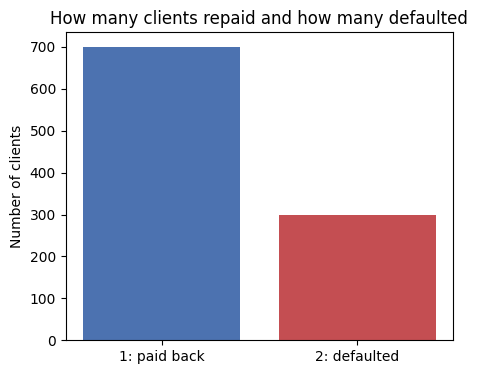

In [ ]:
# How the response variable is distributed
counts = credit['default'].value_counts().sort_index()
print("Class counts:")
print(counts)
print("\nClass share:")
print(credit['default'].value_counts(normalize=True).sort_index().round(3))

plt.figure(figsize=(5, 4))
plt.bar(['1: paid back', '2: defaulted'], counts.values, color=['#4c72b0', '#c44e52'])
plt.title('How many clients repaid and how many defaulted')
plt.ylabel('Number of clients')
plt.show()

The bar chart counts clients in each class, with the height of the bar being the
number of records. There are 700 clients who repaid and 300 who defaulted, that
is 70 percent against 30 percent.

That imbalance is worth keeping in mind for the rest of the notebook. A model
that always answered that the client repays, without looking at a single
variable, would already be right 70 percent of the time, so an accuracy of 70
percent is the floor and not a good result. Any model built here has to beat
that number to be worth anything, and the interesting question is how many of
the 300 defaulters it can find.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The first thing to look at is how the numeric variables behave inside each of
the two classes. If the distribution of a variable is the same for clients who
repaid and clients who defaulted, that variable carries no information about the
response.

In [ ]:
# Summary of the numeric columns
credit.describe().T

,count,mean,std,min,25%,50%,75%,max
months_loan_duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_history,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
default,1000.0,1.300,0.458487,1.0,1.0,1.0,2.00,2.0
dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


Each row of this table is a numeric column and each column a statistic: the
count of values, the mean, the standard deviation, the smallest value, the three
quartiles and the largest value.

The loans last 20.9 months on average. The amount requested averages 3271 DM
with a standard deviation of 2823, and its maximum sits far above the third
quartile, so the variable has a long tail to the right. The clients are 35.5
years old on average. The remaining four columns are small counts rather than
measurements: `installment_rate`, `residence_history` and `existing_credits`
move between 1 and 4, and `dependents` only takes the values 1 and 2.

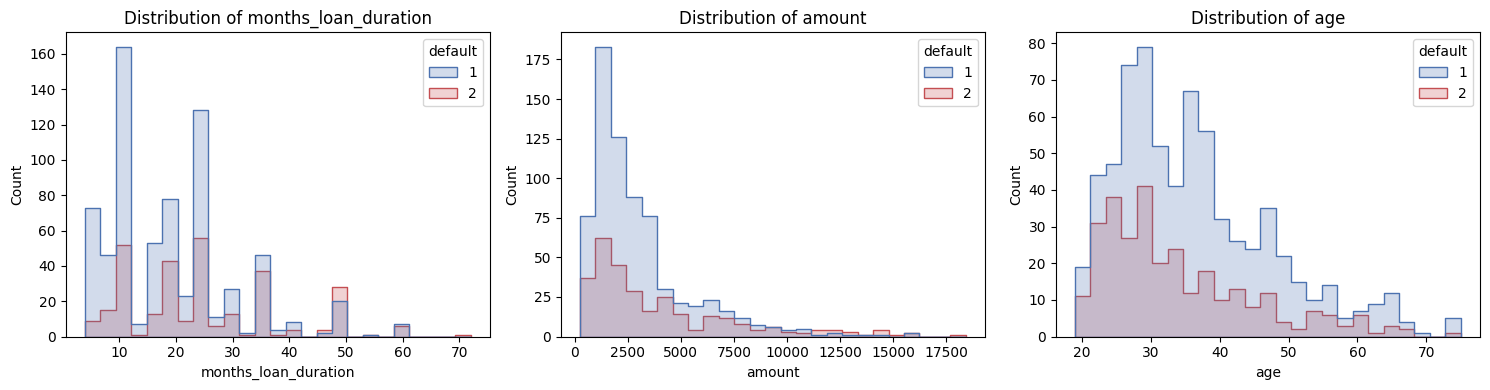

In [ ]:
# Distribution of the three main numeric variables, split by class
numeric_main = ['months_loan_duration', 'amount', 'age']

plt.figure(figsize=(15, 4))
for i, column in enumerate(numeric_main, start=1):
    plt.subplot(1, 3, i)
    sns.histplot(data=credit, x=column, hue='default', bins=25,
                 palette=['#4c72b0', '#c44e52'], element='step')
    plt.title('Distribution of ' + column)
plt.tight_layout()
plt.show()

Each panel is a histogram: the horizontal axis is the value of the variable, the
height of a bar is how many clients fall in that range, and the two colors are
the two classes, blue for the clients who repaid and red for the ones who
defaulted. Because there are more than twice as many clients in the first class,
the blue curve is taller almost everywhere and what matters is the shape, not
the height.

The duration of the loan and the amount both pile up on the left and stretch out
to the right, which is the long tail already visible in the summary table. In
both of them the red curve is shifted slightly to the right of the blue one, so
longer and larger loans default more often. Age behaves the other way around,
with the red curve leaning towards the younger clients.

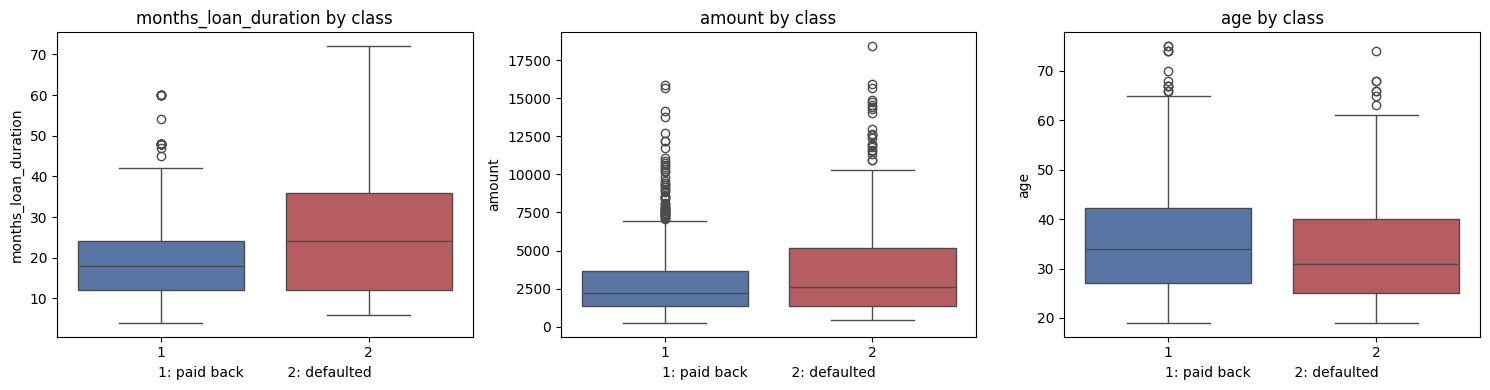

         months_loan_duration  amount   age
default                                    
1                        18.0  2244.0  34.0
2                        24.0  2574.5  31.0


In [ ]:
# The same three variables as box plots, one box per class
plt.figure(figsize=(15, 4))
for i, column in enumerate(numeric_main, start=1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=credit, x='default', y=column,
                hue='default', palette=['#4c72b0', '#c44e52'], legend=False)
    plt.title(column + ' by class')
    plt.xlabel('1: paid back          2: defaulted')
plt.tight_layout()
plt.show()

# The numbers behind the boxes
print(credit.groupby('default')[numeric_main].median())

A box plot summarises a variable with five numbers. The box goes from the first
quartile to the third quartile, so it holds the middle half of the clients, the
line inside the box is the median, the whiskers reach out to the most extreme
values that are still close to the box, and the dots beyond them are the
observations that sit far from the rest.

The medians printed under the plots say the same thing in numbers: the clients
who defaulted asked for longer and larger loans and are younger than the ones
who repaid. The boxes overlap a lot, so none of these three variables separates
the classes on its own, but all three push in a consistent direction.

In [ ]:
# Default rate inside each level of the most promising text variables
for column in ['checking_balance', 'credit_history', 'savings_balance']:
    share = pd.crosstab(credit[column], credit['default'], normalize='index')
    share.columns = ['paid back', 'defaulted']
    print('Default rate by ' + column)
    print(share.round(3))
    print()

Default rate by checking_balance
                  paid back  defaulted
checking_balance                      
1 - 200 DM            0.610      0.390
< 0 DM                0.507      0.493
> 200 DM              0.778      0.222
unknown               0.883      0.117

Default rate by credit_history
                        paid back  defaulted
credit_history                              
critical                    0.829      0.171
delayed                     0.682      0.318
fully repaid                0.375      0.625
fully repaid this bank      0.429      0.571
repaid                      0.681      0.319

Default rate by savings_balance
                 paid back  defaulted
savings_balance                      
101 - 500 DM         0.670      0.330
501 - 1000 DM        0.825      0.175
< 100 DM             0.640      0.360
> 1000 DM            0.875      0.125
unknown              0.825      0.175



Each table takes one text variable, puts one of its levels on every row, and
reports which share of the clients in that row repaid and which share defaulted.
The two numbers of a row add up to 1, so a row with 0.49 in the second column
means that almost half of those clients defaulted.

The balance of the checking account is the strongest signal in the whole
dataset. Clients whose account was overdrawn defaulted 49 percent of the time,
those between 1 and 200 DM 39 percent, those above 200 DM 22 percent, and the
group recorded as unknown only 12 percent. That last group is not a missing
value to be filled in, it means the client has no checking account at this bank,
and it turns out to be the safest group of all.

The credit history table looks backwards at first, because the level named
critical defaults less often than the levels that say the client fully repaid a
previous loan. That is a known trait of this dataset: a client labelled critical
already has a long record at this bank, while a client whose previous loans are
closed is one the bank currently knows nothing about. The savings balance
repeats the pattern of the checking account, with the lowest savings defaulting
the most.

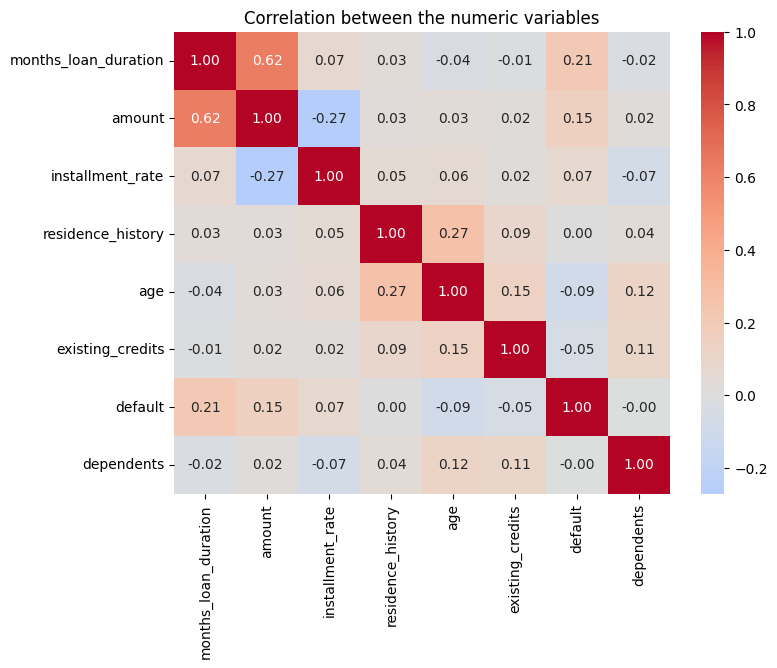

In [ ]:
# Correlation between the numeric variables
numeric_columns = credit.select_dtypes(include='number').columns
correlation = credit[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between the numeric variables')
plt.show()

A correlation heatmap puts the same variables on both axes and colors each cell
with the linear correlation of that pair, from minus one in blue to plus one in
red, with zero in white. The diagonal is always one because every variable is
perfectly correlated with itself. A value near zero means that knowing one
variable says nothing linear about the other.

The only strong pair is the amount with the duration of the loan at 0.62, which
is expected since larger loans are paid over longer terms. The next largest in
absolute value is the installment rate with the amount at -0.27, which says the
same thing from the other side, because a large loan is repaid with a smaller
share of the income. Everything else stays below 0.30.

The row of `default` is worth reading even though the response is not a
continuous variable and this measure is not the right tool for it. It gives 0.21
with the duration, 0.15 with the amount and -0.09 with the age, so the three
variables the box plots pointed at appear here too, in the same direction and
just as weak. Nothing in this table comes close to the 0.49 against 0.12 default
rate that the checking balance produced, which is the reminder that the strength
of this dataset is in its categorical columns and that a correlation matrix
cannot see them.

Trees split one variable at a time and are not disturbed by correlated
predictors the way a regression would be, so no column has to be removed because
of this, but it is useful to know that the amount and the duration carry partly
the same information when their importances are read later.

The heatmap reduces every pair of variables to one number, which hides the shape
of the relationship behind it. The pairplot draws that shape. It is built only
for the three continuous variables, since the remaining four numeric columns
take four values at most and would come out as columns of dots that say nothing.

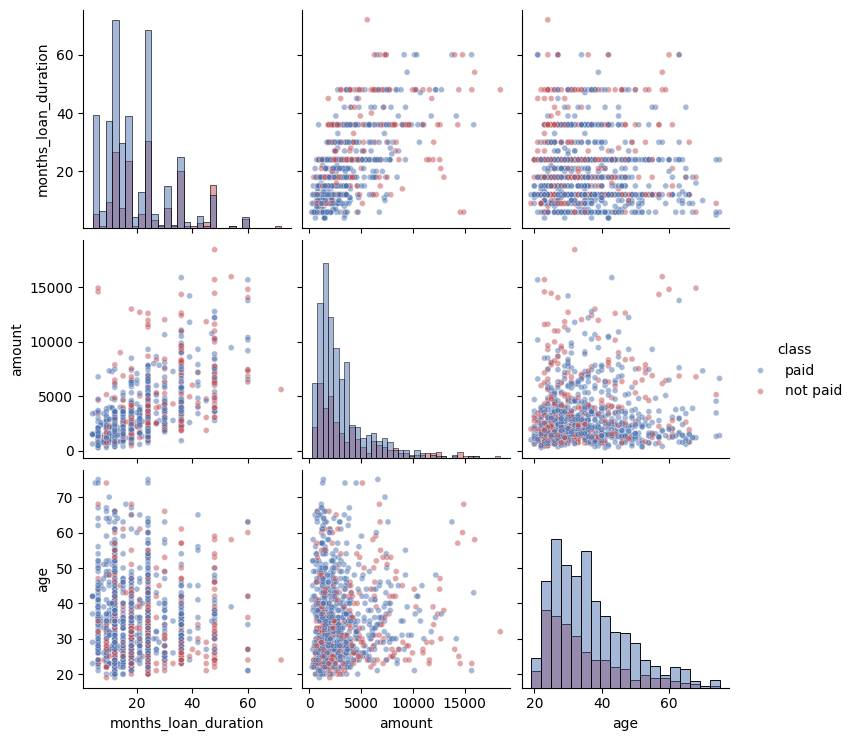

In [ ]:
# Pairwise relationships of the three continuous variables, split by class
continuous = ['months_loan_duration', 'amount', 'age']
pair_data = credit[continuous].copy()
pair_data['class'] = credit['default'].map({1: 'paid', 2: 'not paid'})

sns.pairplot(pair_data, hue='class', diag_kind='hist',
             palette={'paid': '#4c72b0', 'not paid': '#c44e52'},
             plot_kws={'alpha': 0.5, 's': 18})
plt.show()

The grid puts the three variables on both axes. Each cell outside the diagonal
is a scatter plot of one variable against another, with one dot per client and
the color giving the class, and the diagonal holds the histogram of each
variable by itself, since a variable against itself would only draw a straight
line. The grid is symmetric, so the cell above the diagonal and the one below it
hold the same information with the axes swapped.

The amount against the duration is the only pair that shows a relationship. The
cloud climbs from the bottom left to the top right, which is the 0.62 of the
heatmap seen as a shape, and it does so in vertical stripes because the duration
is agreed in round terms, 6, 12, 18, 24, 36 and 48 months, rather than taking
any value. Age against the other two shows no such climb, only a cloud that
fills the space.

The colors are what this plot was drawn for, and they are mixed everywhere. The
red dots lean towards the long durations and the large amounts, and the diagonal
histogram of the age shows them piled on the young side, but there is no region
of any of these three planes that holds defaulters and nothing else. That is the
same conclusion the box plots reached, now for pairs of variables instead of one
at a time, and it sets the expectation for the rest of the notebook: a model
that separates these classes will have to combine many variables, most of them
categorical, and even then the two groups will keep overlapping.

In [ ]:
# The response as a 0 and 1 variable, where 1 is the client of interest
target = (credit['default'] == 2).astype(int)

# The predictors, with every text column turned into indicator columns
predictors = pd.get_dummies(credit.drop(columns='default'))

print("Predictors before encoding:", credit.shape[1] - 1)
print("Predictors after encoding:", predictors.shape[1])
print("Class counts of the recoded response:")
print(target.value_counts().sort_index())

Predictors before encoding: 20
Predictors after encoding: 61
Class counts of the recoded response:
default
0    700
1    300
Name: count, dtype: int64


A decision tree in scikit-learn only accepts numbers, so every text column has
to be turned into numbers first. `get_dummies` replaces a column by one
indicator column per level, holding 1 when the client belongs to that level and
0 otherwise, which is why the 20 original predictors become 61 columns.

The response is recoded at the same time so that 1 means the client defaulted
and 0 means the client repaid. This is only a renaming of the labels, the counts
are still 300 and 700, and it puts the class of interest in the position that
scikit-learn treats as positive when it computes precision, recall and the ROC
curve.

Training records: 800
Test records: 200
Total: 1000

Default share in training: 0.3
Default share in test: 0.3


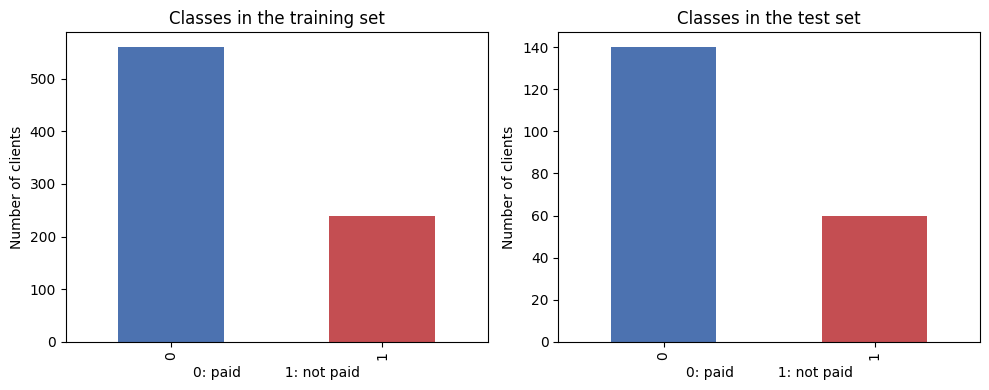

In [ ]:
# Split 80 percent for training and 20 percent for testing, keeping the
# proportion of defaulters identical in both parts
X_train, X_test, y_train, y_test = train_test_split(
    predictors, target, test_size=0.2, random_state=SEED, stratify=target)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Total:", len(X_train) + len(X_test))
print()
print("Default share in training:", round(y_train.mean(), 3))
print("Default share in test:", round(y_test.mean(), 3))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
y_train.value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Classes in the training set')
plt.xlabel('0: paid          1: not paid')
plt.ylabel('Number of clients')

plt.subplot(1, 2, 2)
y_test.value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Classes in the test set')
plt.xlabel('0: paid          1: not paid')
plt.ylabel('Number of clients')
plt.tight_layout()
plt.show()

The model is fitted on one part of the data and judged on another part it has
never seen, otherwise the score would only say how well it memorised. Here 800
records go to training and 200 to testing, and nothing is lost since the two add
up to the original 1000.

The split is stratified, which means the share of defaulters is forced to be the
same in both parts. Both bar charts show the same 70 to 30 shape and both means
print 0.3, so a difference between the two sets later on cannot be blamed on one
of them holding more defaulters than the other.

## Machine Learning Model (CRISP-DM 4: Modeling)

One decision tree is trained on the 800 training records with the standard
recipe: the default settings of `DecisionTreeClassifier`, the gini criterion,
and the only tuned parameter being the depth, chosen by cross validation on the
AUC.

A tree that is allowed to grow without limit keeps splitting until every leaf is
pure, which means it ends up describing the training records one by one instead
of describing the population. The depth is therefore chosen before fitting, by
trying several values and keeping the one that scores best on data the tree did
not use for that particular fit.

max_depth 2   mean AUC 0.6878
max_depth 3   mean AUC 0.6883


max_depth 4   mean AUC 0.6804
max_depth 5   mean AUC 0.6793
max_depth 6   mean AUC 0.6861
max_depth 7   mean AUC 0.6787


max_depth 8   mean AUC 0.6843
max_depth 9   mean AUC 0.6577


max_depth 10   mean AUC 0.6427
max_depth 11   mean AUC 0.6408
max_depth 12   mean AUC 0.6438

Best depth: 3


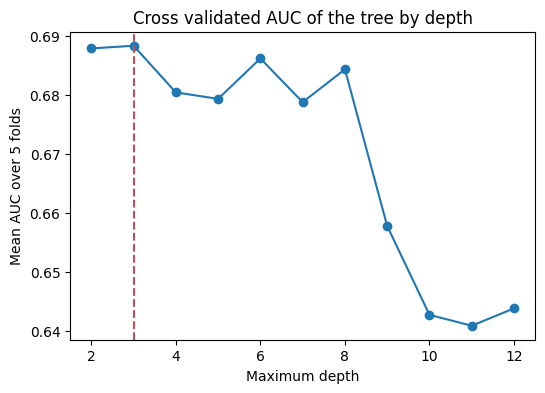

In [ ]:
# Try several depths and score each one with 5 fold cross validation on the
# training set only, so the test set stays untouched
depths = range(2, 13)
scores = []
for depth in depths:
    candidate = DecisionTreeClassifier(criterion='gini', max_depth=depth,
                                       random_state=1)
    score = cross_val_score(candidate, X_train, y_train, cv=5,
                            scoring='roc_auc').mean()
    scores.append(score)
    print("max_depth", depth, "  mean AUC", round(score, 4))

best_depth = list(depths)[int(np.argmax(scores))]
print("\nBest depth:", best_depth)

plt.figure(figsize=(6, 4))
plt.plot(list(depths), scores, marker='o')
plt.axvline(best_depth, color='#c44e52', linestyle='--')
plt.title('Cross validated AUC of the tree by depth')
plt.xlabel('Maximum depth')
plt.ylabel('Mean AUC over 5 folds')
plt.show()

Cross validation cuts the training set into five blocks, fits the tree five
times leaving one block out each time, and scores it on the block that was left
out. The number reported for each depth is the average of those five scores, so
it estimates how the tree would do on new clients without ever touching the test
set. The score used is the AUC, explained in the evaluation section, where 0.5
means the model is guessing and 1 means it separates the classes perfectly.

The best depth is 3, with a mean AUC of 0.6883. That number should be read next
to its neighbours rather than on its own, because the curve is almost flat from
depth 2 to depth 8, where the scores go 0.6878, 0.6883, 0.6804, 0.6793, 0.6861,
0.6787 and 0.6843. Depth 3 wins over depth 2 by 0.0005, which is noise, so the
honest reading is not that depth 3 is the right size but that no small tree
manages to score much above 0.68 on this data.

From depth 9 onwards the curve does fall clearly, to 0.6577 and then to 0.6408
at depth 11. That fall is overfitting made visible: the deeper trees fit the
training blocks better and the held out block worse. Depth 3 is the value used
from here on.

In [ ]:
# Train the decision tree with the depth chosen above
tree_model = DecisionTreeClassifier(criterion='gini', max_depth=best_depth,
                                    random_state=1)
tree_model.fit(X_train, y_train)

print("Accuracy on training:", round(tree_model.score(X_train, y_train), 3))
print("Accuracy on test:", round(tree_model.score(X_test, y_test), 3))

Accuracy on training: 0.708
Accuracy on test: 0.695


The tree is now fitted on the 800 training clients. It scores 0.708 on the
training records and 0.695 on the test ones, and the two numbers being so close
says that this tree is not memorising its training data.

The problem is the other comparison. Answering that every client pays, without
looking at a single variable, would score 0.70 on this test set, since 140 of
the 200 clients did pay. The tree scores 0.695, which is below that. Whatever it
learned, it is not buying any accuracy, and the confusion matrix in the
evaluation section shows what it is doing instead.

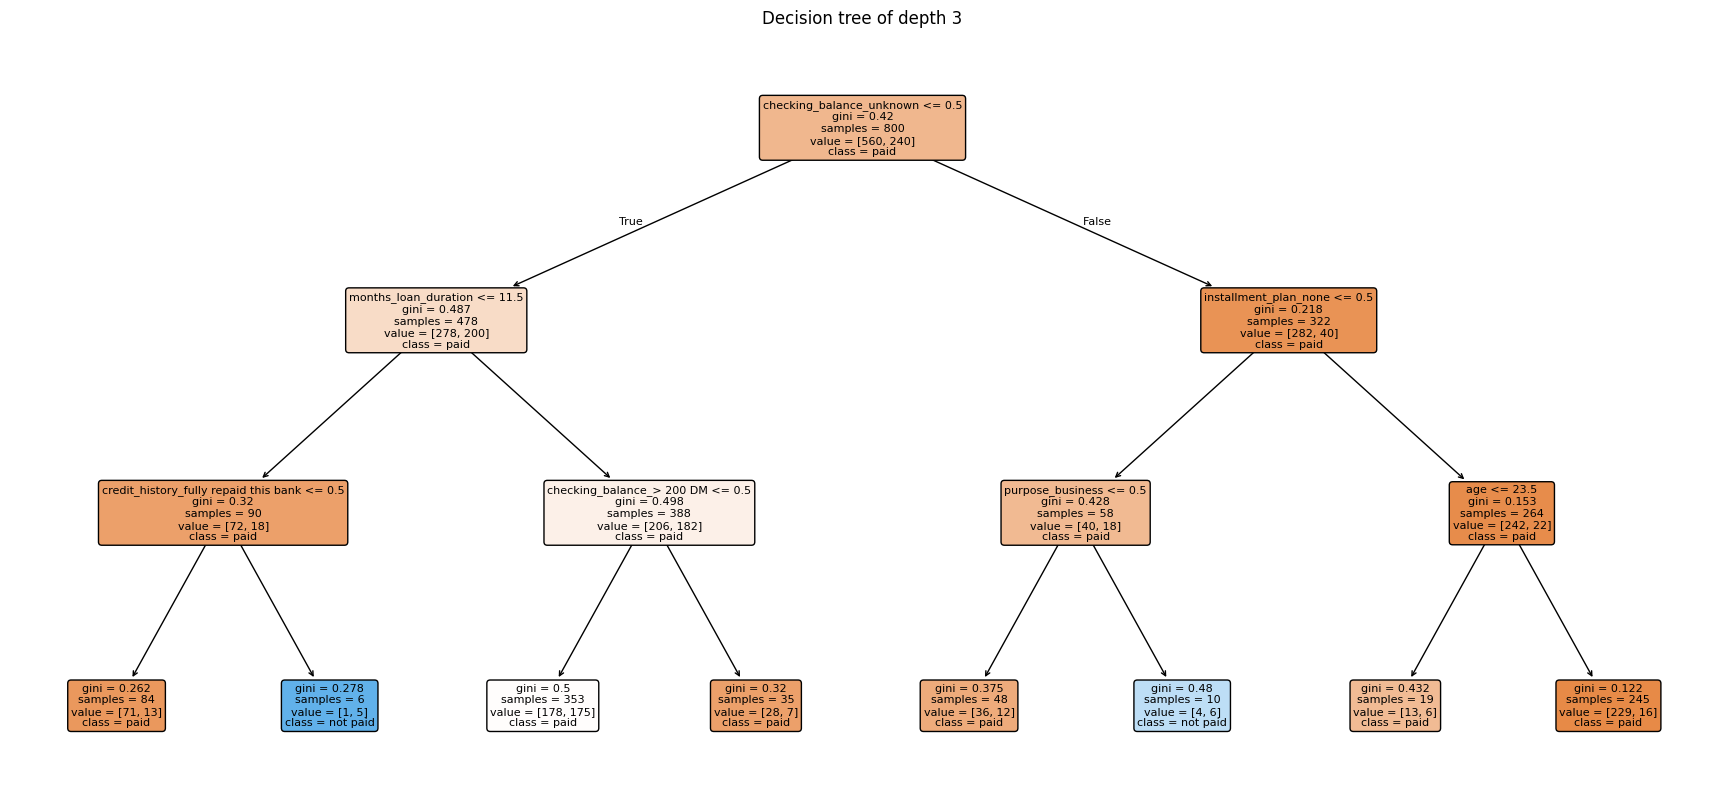

In [ ]:
# Draw the tree
plt.figure(figsize=(22, 10))
plot_tree(tree_model, feature_names=list(predictors.columns),
          class_names=['paid', 'not paid'], filled=True, rounded=True,
          fontsize=8, impurity=True)
plt.title('Decision tree of depth ' + str(best_depth))
plt.show()

Every box in the drawing is a node. The first line is the question asked at that
node, and a client goes left when the answer is true and right when it is false.
Since the text variables were turned into indicator columns, a question like
`checking_balance_unknown <= 0.5` simply asks whether the client does not belong
to that level.

The second line is the gini impurity of the node, the measure the tree tries to
lower with every split. It is 0 when every client in the node belongs to the
same class and 0.5 when the node is split half and half, so a node with a low
gini is one where the answer is clear. That is the criterion passed to the model
as `criterion='gini'`. Then `samples` counts the training clients that reach the
node, `value` gives the share of those clients in each class, in the order paid
first and not paid second, so multiplying `value` by `samples` recovers the two
counts. `class` is the answer the node would give, which is simply whichever of
the two shares in `value` is larger. The color follows that same majority,
orange for the clients who paid and blue for the ones who did not, and the
stronger the color the purer the node.

The two labels come from the response built in the preparation section, where 0
means the client paid the loan back and 1 means the client defaulted. They are
not a value of any column of the dataset, and in particular the level named
repaid that appears inside `credit_history` is a predictor about previous loans,
not the variable being predicted.

The root holds the 800 training clients with `value = [0.7, 0.3]`, which is 560
who paid and 240 who did not, and a gini of 0.42, and it splits on whether the
client has an unknown checking balance, the variable the exploration had already
pointed at. What matters is what happens below. Only two of the eight leaves
come out blue: one with `samples = 6` and `value = [0.167, 0.833]`, that is 1
client who paid and 5 who did not, and one with `samples = 10` and
`value = [0.4, 0.6]`, that is 4 and 6. Between them they hold 11 defaulters out
of the 240 in training, and the other 229 sit inside leaves labelled paid.

The clearest case is the leaf with `samples = 353` and `value = [0.504, 0.496]`,
which is 178 clients who paid and 175 who did not. Its gini is 0.5, the maximum,
so that group is an even mix of clients who paid and clients who did not, and
the tree still has to print one label for all 353 of them. It prints paid, by a
margin of three clients. Reading `class` as a description of the clients in a
node is therefore the easy mistake to make, and the honest reading of a node is
its `value` and its gini.

                             Variable  Importance
             checking_balance_unknown    0.522390
                 months_loan_duration    0.165936
            checking_balance_> 200 DM    0.087381
credit_history_fully repaid this bank    0.080897
                installment_plan_none    0.076882
                                  age    0.034708
                     purpose_business    0.031806
                    residence_history    0.000000
                     installment_rate    0.000000
              checking_balance_< 0 DM    0.000000


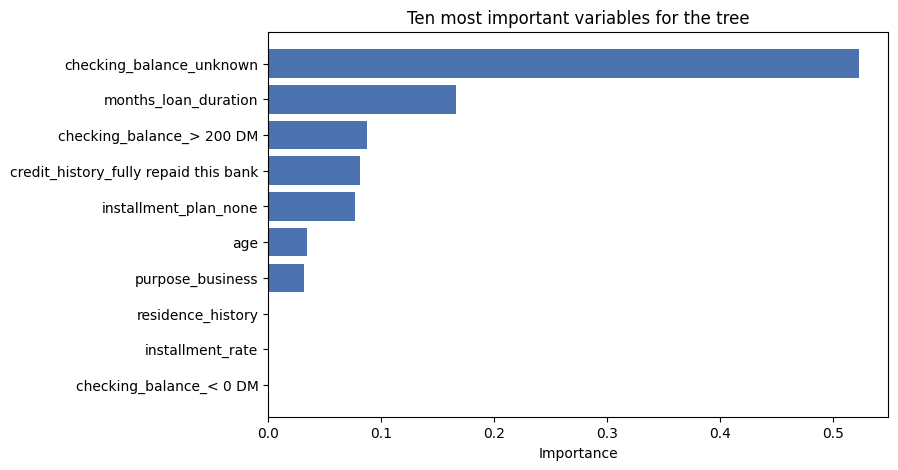

In [ ]:
# Importance of each variable for the tree
tree_importances = pd.DataFrame({
    'Variable': tree_model.feature_names_in_,
    'Importance': tree_model.feature_importances_
}).sort_values('Importance', ascending=False)

top_tree = tree_importances.head(10)
print(top_tree.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(top_tree['Variable'][::-1], top_tree['Importance'][::-1], color='#4c72b0')
plt.title('Ten most important variables for the tree')
plt.xlabel('Importance')
plt.show()

The importance of a variable is how much the splits made on it reduced the
impurity of the nodes, weighted by how many training clients passed through
those splits, and the importances of all the variables add up to 1. A variable
with importance 0 was never used.

This tree is extremely concentrated. The indicator of an unknown checking
balance alone takes 0.522 of the total, the duration of the loan takes 0.166 and
the indicator of a checking balance above 200 DM takes 0.087. Only 7 of the 61
columns get any importance at all, so 54 of them were never used.

That is what makes a single tree easy to explain and, at the same time, fragile.
Three levels of questions can only look at a handful of variables, and
everything the dataset knows about savings, employment, property or the purpose
of the loan is simply discarded. The evaluation section shows that this
particular tree has a worse problem than being fragile.

## Evaluation (CRISP-DM 5)

The tree is now applied to the 200 test clients it has never seen, of which 60
defaulted and 140 repaid. The first tool is the confusion matrix, which crosses
the real class with the predicted one. Its four cells are the clients correctly
predicted as repaying, the clients wrongly flagged as defaulters, the defaulters
the model let through, and the defaulters it caught. For this problem the third
cell is the expensive one.

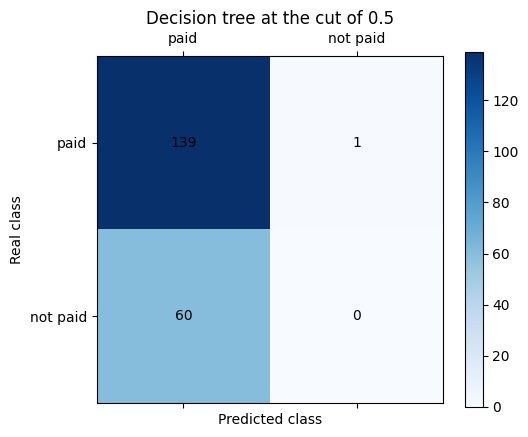

              precision    recall  f1-score   support

        paid      0.698     0.993     0.820       140
    not paid      0.000     0.000     0.000        60

    accuracy                          0.695       200
   macro avg      0.349     0.496     0.410       200
weighted avg      0.489     0.695     0.574       200

Cost under the five to one rule: 301


In [ ]:
# Probability of default that the tree assigns to every test client
tree_scores = tree_model.predict_proba(X_test)[:, 1]

# One single rule turns those probabilities into decisions. Every matrix, table
# and cost of this section goes through it, so the model is always judged under
# an explicit cut and never through predict(), which resolves a probability of
# exactly 0.5 towards the class that pays
DECISION_THRESHOLD = 0.5

def decisions_at(scores, threshold):
    return (scores >= threshold).astype(int)

# Cost of the two kinds of error, as stated in the problem analysis
COST_MISSED_DEFAULTER = 5
COST_REJECTED_CLIENT = 1

def total_cost(y_true, y_predicted):
    matrix = confusion_matrix(y_true, y_predicted, labels=[0, 1])
    missed = matrix[1, 0]      # a defaulter predicted as paying
    rejected = matrix[0, 1]    # a good client predicted as defaulting
    return missed * COST_MISSED_DEFAULTER + rejected * COST_REJECTED_CLIENT

tree_predictions = decisions_at(tree_scores, DECISION_THRESHOLD)
tree_matrix = confusion_matrix(y_test, tree_predictions)

labels = ['paid', 'not paid']
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.matshow(tree_matrix, cmap=plt.cm.Blues)
for i in range(tree_matrix.shape[0]):
    for j in range(tree_matrix.shape[1]):
        ax.text(x=j, y=i, s=tree_matrix[i, j], va='center', ha='center')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Real class')
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_title('Decision tree at the cut of 0.5')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print(classification_report(y_test, tree_predictions,
                            target_names=labels, digits=3, zero_division=0))
print("Cost under the five to one rule:", total_cost(y_test, tree_predictions))

The rows of the matrix are the real class and the columns the predicted one, so
the diagonal holds the correct answers. The report under the plot turns the four
cells into three rates, computed here for the defaulters. Precision is how many
of the clients flagged as defaulters really defaulted, recall is how many of the
real defaulters the model flagged, and the F1 is the balance between those two.

The tree does not classify anything. Of the 140 clients who paid it predicts
paid for 139, and of the 60 who defaulted it catches 0. Its recall on the
defaulters is 0.000, and so is its precision, because the single client it did
flag turned out to be one who paid.

Its accuracy of 0.695 has to be read against the right reference. Answering that
every client pays, without looking at a single variable, would score 0.700 on
this test set, since 140 of the 200 clients did pay. The tree scores 0.695, which
is below that, so the model is not only equivalent to the trivial answer, it is
one client worse than it.

The drawing of the tree already announced this. Only two of its eight leaves
predict a default and they hold 6 and 10 training clients between them, so no
test defaulter landed in either.

The last line prices the matrix under the five to one rule of the problem
analysis: 60 defaulters approved at five units each plus one good client
rejected at one unit, which is 301 units on these 200 clients. That number is
the reference for the rest of the section.

AUC of the decision tree: 0.693
Different probabilities the tree assigns to the 200 test clients:
[0.065 0.155 0.2   0.25  0.316 0.496 0.6  ]


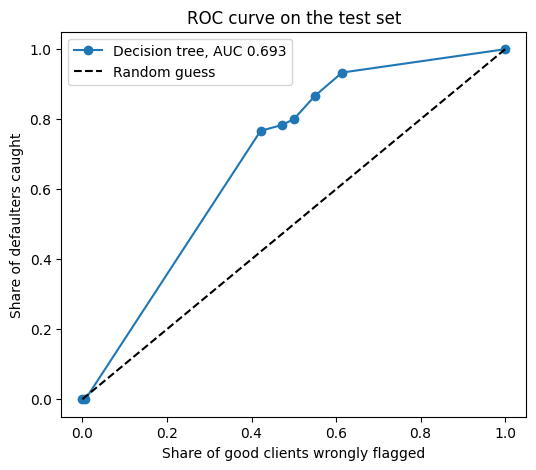

In [ ]:
# ROC curve, built from the probabilities computed above
tree_auc = roc_auc_score(y_test, tree_scores)
print("AUC of the decision tree:", round(tree_auc, 3))
print("Different probabilities the tree assigns to the 200 test clients:")
print(np.round(np.sort(np.unique(tree_scores)), 3))

fpr, tpr, _ = roc_curve(y_test, tree_scores)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, marker='o',
         label='Decision tree, AUC ' + str(round(tree_auc, 3)))
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.axhline(0, color='none')
plt.xlabel('Share of good clients wrongly flagged')
plt.ylabel('Share of defaulters caught')
plt.title('ROC curve on the test set')
plt.legend()
plt.show()

The tree does not really answer yes or no, it returns a probability of default,
and the prediction of the previous cell came from cutting that probability at
0.5. The ROC curve redoes the comparison for every possible cut: the horizontal
axis is the share of good clients wrongly flagged and the vertical one the share
of defaulters caught, and each point of the curve is one cut. The diagonal is
what a coin flip would draw. The area under the curve, the AUC, summarises it in
one number, and it can be read as the probability that the model gives a higher
score to a random defaulter than to a random client who pays.

The AUC is 0.693. That is not a good value, but it is clearly above the 0.5 of a
coin flip, so the tree does carry information: taking one defaulter and one
client who paid at random, it scores the defaulter higher about seven times out
of ten.

Put that next to the recall of 0.000 of the previous cell and the contradiction
is the result of this section. The same model that ranks clients better than
chance catches none of them. It is not failing to tell a defaulter from a good
client, it is failing at the step that turns that ordering into an answer.

The list of probabilities printed above is the whole explanation. The tree has
eight leaves, so it can only produce eight different scores, and on these 200
clients it produces seven: 0.065, 0.155, 0.200, 0.250, 0.316, 0.496 and 0.600.
Six of those seven are below 0.5. Cutting at 0.5 therefore flags only the clients
who fall in the single leaf that scores 0.600, and exactly one test client landed
there. The cut of 0.5 is not wrong in general, it is wrong for a model whose
probabilities almost never reach it, and that is a consequence of the 70 to 30
imbalance measured in the exploration: with only 30 percent of defaulters in the
data, almost no group of clients has a majority of them.

The curve is a staircase of seven steps for the same reason, one step per
distinct score, instead of the smooth line a model with many possible outputs
would draw.

In [ ]:
# What happens when the cut is moved away from 0.5, using the same decision
# rule as the confusion matrix
rows = []
for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60]:
    predicted = decisions_at(tree_scores, threshold)
    rows.append({
        'Threshold': threshold,
        'Accuracy': round(accuracy_score(y_test, predicted), 3),
        'Precision': round(precision_score(y_test, predicted,
                                           zero_division=0), 3),
        'Recall': round(recall_score(y_test, predicted), 3),
        'F1': round(f1_score(y_test, predicted), 3),
        'Missed': int(((y_test == 1) & (predicted == 0)).sum()),
        'Rejected': int(((y_test == 0) & (predicted == 1)).sum()),
        'Cost': total_cost(y_test, predicted)
    })
print(pd.DataFrame(rows).to_string(index=False))

 Threshold  Accuracy  Precision  Recall    F1  Missed  Rejected  Cost
      0.05     0.300      0.300   1.000 0.462       0       140   140
      0.10     0.550      0.394   0.933 0.554       4        86   106
      0.15     0.550      0.394   0.933 0.554       4        86   106
      0.20     0.575      0.403   0.867 0.550       8        77   117
      0.30     0.605      0.416   0.783 0.543      13        66   131
      0.40     0.635      0.438   0.767 0.558      14        59   129
      0.50     0.695      0.000   0.000 0.000      60         1   301
      0.60     0.695      0.000   0.000 0.000      60         1   301


Each row applies a different cut to the same probabilities and recounts the
errors, with the last three columns counting the two mistakes directly and the
cost they add up to. Nothing about the tree changes from one row to the next.
It is the same eight leaves and the same seven scores, read against a different
number.

The transformation is complete. At the cut of 0.5 the tree misses 60 defaulters
and costs 301 units. At 0.10 it misses 4, and its recall goes from 0.000 to
0.933 and its cost down to 106 units, a third of what the default cut costs.

What it pays for that is in the column next to it: it rejects 86 of the 140
clients who would have paid, so its precision stays at 0.394 and its accuracy
falls from 0.695 to 0.550. Under the five to one rule that trade is worth making,
because 82 additional rejected clients cost 82 units and the 56 defaulters
recovered save 280, but it is a very different way of running a credit desk and
the bank has to accept it explicitly.

Two rows are worth reading on their own. At 0.05 the recall is 1.000 and the
tree rejects all 140 good clients, which is simply refusing every applicant, and
its accuracy of 0.300 is the share of defaulters in the test set. And the row at
0.60 is identical to the row at 0.50 because the highest score the tree produces
is exactly 0.600 and the comparison includes it, so the single client it flags is
the same one in both.

One warning before the next cell. These cuts are being tried on the test set,
which is the only data left that the model has not seen, so the numbers in this
table are the best case rather than an estimate of what a new client would get.
The results section states what a correct procedure would look like.

Cost at the default cut of 0.5: 301
Cheapest cut: 0.07  cost: 106


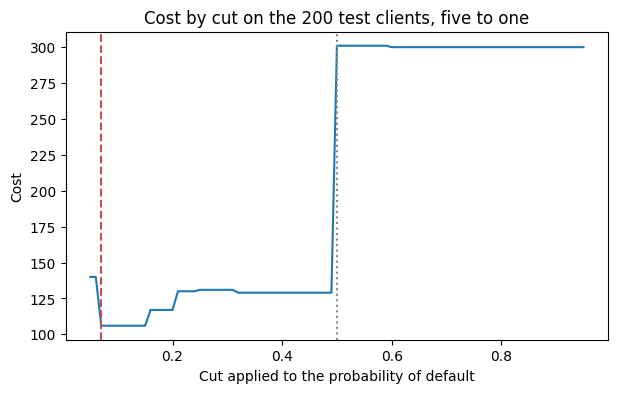

In [ ]:
# Cost of every cut under the five to one rule
def cost_of_decisions(scores, threshold):
    return total_cost(y_test, decisions_at(scores, threshold))

grid = np.arange(0.05, 0.96, 0.01)
tree_curve = [cost_of_decisions(tree_scores, t) for t in grid]
best_cut = grid[int(np.argmin(tree_curve))]

print("Cost at the default cut of 0.5:", cost_of_decisions(tree_scores, 0.5))
print("Cheapest cut:", round(best_cut, 2),
      " cost:", cost_of_decisions(tree_scores, best_cut))

plt.figure(figsize=(7, 4))
plt.plot(grid, tree_curve)
plt.axvline(best_cut, color='#c44e52', linestyle='--')
plt.axvline(0.5, color='#888888', linestyle=':')
plt.title('Cost by cut on the 200 test clients, five to one')
plt.xlabel('Cut applied to the probability of default')
plt.ylabel('Cost')
plt.show()

This plot puts the cut on the horizontal axis and the total cost of the resulting
decisions on the vertical one, counting five units for every defaulter approved
and one unit for every good client turned away. Lower is better, the dotted line
marks the default cut of 0.5 and the dashed one the cheapest cut found.

The curve is a staircase with as many steps as the tree has distinct scores, and
it is far from flat. It costs 106 units at its minimum, at a cut of 0.07, and it
costs 301 at the default cut, so where the line is drawn is worth roughly three
times the model itself on this test set.

The right end shows the tree running out of material. Once the cut passes 0.600
the tree flags nobody at all and the cost settles at 300 units, which is what
approving all 60 defaulters costs. From there no cut can do anything, because
there is no score left above the line.

This is the practical conclusion of the notebook: a decision tree fitted with the
default recipe on an imbalanced dataset produces a usable ordering and an
unusable decision, and the cheapest place to fix that is the cut and not the
model. The fix, however, is limited by how coarse the tree is. With seven
distinct scores there are only seven decisions available, so the curve moves in
jumps and there is no fine control between them.

## Results (CRISP-DM 6: Deployment)

A single decision tree was trained on 800 clients of the German credit dataset
and judged on the 200 that it never saw, of which 60 defaulted. Its depth of 3
was chosen by five fold cross validation on the AUC inside the training set, and
everything else was left at the default settings of the library.

The model, as it comes out of that standard recipe, is not usable. On the test
set it reaches an accuracy of 0.695 and an AUC of 0.693, but it catches 0 of the
60 defaulters, and both its precision and its recall on that class are 0.000. Its
accuracy is below the 0.700 that answering paid to every applicant would give,
so it is one client worse than having no model at all, and under the five to one
cost of the problem it costs 301 units.

The diagnosis is not that the tree learned nothing. Its AUC of 0.693 says it
ranks a defaulter above a client who pays about seven times out of ten, which is
clearly better than chance. What fails is the step that turns that ranking into
an answer. The tree has eight leaves and produces seven different scores on the
test set, of which six sit below 0.5, so the default cut flags only the single
leaf that reaches 0.600. That is a direct consequence of the imbalance measured
in the exploration: with 30 percent of defaulters in the data, almost no group of
clients ends up with a majority of them, and a leaf votes by majority.

Moving the cut is what makes the model do something. At a cut of 0.10 the tree
catches 56 of the 60 defaulters, a recall of 0.933, and its cost falls from 301
to 106 units, a third of what the default cut costs. The cheapest cut on this
test set is 0.07, also at 106 units. The price is explicit: 86 of the 140 good
clients are rejected, precision stays at 0.394 and accuracy falls to 0.550, so
roughly six of every ten applicants the tree flags would have paid.

Two things should be said about that number before anyone uses it. The cut of
0.07 was chosen by looking at the same 200 test clients it is then evaluated on,
so 106 units is optimistic and not an estimate of what new clients would cost. A
correct procedure would pick the cut on a third split, or inside the cross
validation, exactly as the depth was picked. And the tree is very coarse: seven
distinct scores mean seven possible decisions, so the cost curve moves in jumps
and there is no fine control between them.

The recommendation is therefore limited and it is stated as such. This tree can
be used as a rough score that orders applicants by risk, read at a cut set from
the cost the bank assigns to each error and never at the default 0.5, and always
in front of a person rather than as an automatic rejection. It should not be
deployed as a decision rule on its own. Its three levels of questions are its one
real advantage, since they can be read out loud to an applicant, and its
importances say that the whole decision rests on the balance of the checking
account, which takes 0.522 of the total, the duration of the loan with 0.166 and
the indicator of a balance above 200 DM with 0.087.

Four limitations should be stated. The test set holds 60 defaulters, so one
client moving from one cell of the confusion matrix to another changes recall by
1.7 points and every number above carries that much noise. The cross validated
curve is flat, between 0.678 and 0.688 of AUC for every depth from 2 to 8, so
the depth was chosen among sizes that the data does not really distinguish, and
the procedure was picking between equally weak trees rather than finding a good
one. The tree uses 7 of the 61 columns and leaves 54 untouched, so everything the
dataset records about savings, employment, property or the purpose of the loan is
discarded. And the data is old and German, with amounts in Deutsche Mark, so the
risk it encodes does not transfer to another market without being refitted.